# Part 3 — Scalable Processing

**BFT65B — Big Data Analytics in Finance | Student ID: 11230945**

Compare equivalent pandas, Polars and PySpark transformations on the verified Silver financial panel. Evaluate filtered aggregation, adjacent-quarter growth and state–quarter peer joins through output parity, execution plans, processing latency, memory consumption, synthetic scale-up and thread sensitivity. Outcome labels and retrospective audit fields remain outside these experiments.

## 1. Repository and runtime
Use a CPU runtime and Java 17 or later. Install the pinned environment before importing the engines. Spark runs locally, not on a distributed cluster.

In [1]:
from pathlib import Path
import os, sys, subprocess, json, shutil
REPO_URL = "https://github.com/NguyenDuong0508/11230945.git"
REPO = Path("/content/11230945")
if not REPO.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)
else:
    assert subprocess.check_output(["git", "remote", "get-url", "origin"], cwd=REPO, text=True).strip() == REPO_URL
    subprocess.run(["git", "pull", "--ff-only"], cwd=REPO, check=True)
print("Git revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO, text=True).strip())
java = shutil.which("java")
if java is None:
    raise RuntimeError("Java 17 or later is required")
os.environ["JAVA_HOME"] = str(Path(java).resolve().parents[1])
print(subprocess.run([java,"-version"],check=True,capture_output=True,text=True).stderr)
subprocess.run([sys.executable,"-m","pip","install","-r",str(REPO/"requirements.txt")],check=True)
def command(script,*args):
    result = subprocess.run([sys.executable,str(REPO/script),*map(str,args)],cwd=REPO,text=True,capture_output=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    result.check_returncode()

Git revision: 9607d142ad33ec5a0490765b32aedec99cd609e9
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)



## 2. Mandatory offline validation
Run the complete repository suite, including actual Parquet and Spark integration. Failures and skipped tests block progression.

In [2]:
import xml.etree.ElementTree as ET
TESTS_PASSED = False
result_path = Path("/content/part3_tests.xml")
result_path.unlink(missing_ok=True)
result = subprocess.run([sys.executable,"-m","pytest","-q","-ra","--tb=short","--show-capture=no",f"--junitxml={result_path}","tests"],cwd=REPO,env=dict(os.environ,PYTEST_DISABLE_PLUGIN_AUTOLOAD="1",SPARK_LOCAL_IP="127.0.0.1",PYSPARK_PYTHON=sys.executable),capture_output=True,text=True)
print(result.stdout)
if result.stderr: print(result.stderr)
if not result_path.is_file(): raise RuntimeError("Missing pytest report")
cases=list(ET.parse(result_path).getroot().iter("testcase"))
problems=[(case,node) for case in cases for node in list(case) if node.tag in ("failure","error","skipped")]
for case,node in problems:
    print(case.get("classname"),case.get("name"),node.tag,node.get("message"),node.text or "")
if result.returncode or not cases or problems: raise RuntimeError("Offline validation failed; inspect diagnostics")
TESTS_PASSED=True
print(f"Mandatory offline validation: PASS ({len(cases)} tests, zero skips)")

........................................................................ [ 50%]
......................................................................   [100%]
----------------- generated xml file: /content/part3_tests.xml -----------------
142 passed in 366.70s (0:06:06)

Mandatory offline validation: PASS (142 tests, zero skips)


## 3. Verified Silver input and experiment scope
Resolve the active panel, check its source lineage and use only its financial partitions. All scales share the same eight-column projection and quarter-wise Snappy layout. Synthetic replicas have disjoint CERTs and preserve within-bank history.

In [4]:
from google.colab import drive
drive.mount("/content/drive")
WORKSPACE = Path("/content/drive/MyDrive/11230945")
SCRATCH = Path("/content/fdic_processing_scratch")
assert TESTS_PASSED
assert not (WORKSPACE/"pending_source.json").exists()
command("run_part2.py","verify","--workspace",WORKSPACE)
pointer=json.loads((WORKSPACE/"active_panel.json").read_text())
SILVER=WORKSPACE/pointer["path"]
manifest=json.loads((SILVER/"manifest.json").read_text())
assert manifest["state"]=="VERIFIED" and manifest["summary"]["quarters"]==170
print("Silver manifest SHA-256:",pointer["manifest_sha256"])
print("Observed rows:",f"{manifest['summary']['panel_rows']:,}")
print("Planned logical rows:",{f"{s}x":s*manifest['summary']['panel_rows'] for s in (1,5,10)})
print("Local disk free (GiB):",round(shutil.disk_usage('/content').free/2**30,2))
print("Protocol: 24 scenarios; 24 warm-ups; 72 measured trials; 15 untimed plan captures")

Mounted at /content/drive
{
  "status": "PASS",
  "path": "/content/drive/MyDrive/11230945/silver/2026-11-26T090020_073907Z_4229b8e0",
  "summary": {
    "asset_to_null": 0,
    "availability_assumption_days": 90,
    "bronze_failure_rows": 4117,
    "bronze_institution_rows": 27838,
    "distinct_certs": 24064,
    "event_diagnostics": {
      "assistance_records": 593,
      "duplicated_fin_values": 61,
      "end_dates_after_study_end": 4284,
      "failure_dates_before_first_report": 2,
      "failure_dates_before_last_report": 272,
      "failure_type_records": 3524,
      "invalid_or_missing_failure_dates": 0,
      "linked_distinct_failure_cert_dates_through_study_end": 2842,
      "linked_distinct_failure_certs_through_study_end": 2839,
      "missing_cert_failure_source_records": 488,
      "nonpositive_cert_failure_source_records": 0,
      "source_failure_records": 4117,
      "unknown_resolution_records": 0,
      "unknown_resolution_values": [],
      "unlinked_failure_typ

## 4. Execute the controlled benchmark
Stage and verify the projected files locally; run isolated scenarios. A warm-up precedes three measured invocations per scenario. Spark is run at actual scale; pandas and Polars are measured at all scales. No failed or mismatched scenario is silently omitted.

In [5]:
assert TESTS_PASSED
# Stream progress and error diagnostics into the saved notebook output.
cmd = [sys.executable,str(REPO/"run_part3.py"),"run","--workspace",str(WORKSPACE),"--scratch",str(SCRATCH)]
with subprocess.Popen(cmd,cwd=REPO,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1) as process:
    for line in process.stdout:
        print(line,end="",flush=True)
    if process.wait()!=0:
        raise RuntimeError("Benchmark failed; inspect the worker diagnostics above")

1/24 5x_polars_quarter_summary_2t: complete
2/24 1x_pyspark_peer_join_2t: complete
3/24 1x_pandas_quarter_summary_2t: complete
4/24 1x_polars_adjacent_growth_2t: complete
5/24 1x_polars_quarter_summary_2t: complete
6/24 1x_polars_adjacent_growth_1t: complete
7/24 5x_pandas_quarter_summary_2t: complete
8/24 10x_pandas_quarter_summary_2t: complete
9/24 10x_polars_peer_join_2t: complete
10/24 10x_pandas_peer_join_2t: complete
11/24 10x_pandas_adjacent_growth_2t: complete
12/24 5x_polars_peer_join_2t: complete
13/24 1x_polars_peer_join_1t: complete
14/24 1x_pandas_peer_join_2t: complete
15/24 1x_pandas_adjacent_growth_2t: complete
16/24 10x_polars_quarter_summary_2t: complete
17/24 1x_polars_quarter_summary_1t: complete
18/24 5x_pandas_peer_join_2t: complete
19/24 5x_pandas_adjacent_growth_2t: complete
20/24 5x_polars_adjacent_growth_2t: complete
21/24 1x_pyspark_adjacent_growth_2t: complete
22/24 1x_polars_peer_join_2t: complete
23/24 10x_polars_adjacent_growth_2t: complete
24/24 1x_pyspa

## 5. Verify and resolve measured evidence
Recompare all saved trial results, check source lineage and checksums, then read the evidence for presentation. Benchmark replicas are not retained as downstream data.

In [6]:
command("run_part3.py","verify","--workspace",WORKSPACE)
import hashlib
p=json.loads((WORKSPACE/"active_processing.json").read_text())
EVIDENCE=WORKSPACE/p["path"]
with (EVIDENCE/"manifest.json").open("rb") as f:
    assert hashlib.file_digest(f,"sha256").hexdigest()==p["manifest_sha256"]
evidence=json.loads((EVIDENCE/"manifest.json").read_text())
assert evidence["silver_manifest_sha256"]==pointer["manifest_sha256"]
assert evidence["state"]=="VERIFIED" and evidence["measured_trials"]==72
print(json.dumps({k:v for k,v in evidence.items() if k!="files"},indent=2))
print(json.dumps(json.loads((EVIDENCE/"environment.json").read_text()),indent=2))

Processing evidence: PASS /content/drive/MyDrive/11230945/processing_evidence/2026-11-26T092759_952862Z_1183066e
Measured trials: 72

{
  "code_revision": "9607d142ad33ec5a0490765b32aedec99cd609e9",
  "created_utc": "2026-11-26T09:37:43.615279+00:00",
  "measured_trials": 72,
  "scenarios": 24,
  "seed": 11230945,
  "silver_manifest_sha256": "f069efe97c0c05f8389e06acf6954536343726bdc3f15018ecdd073de43d59dc",
  "source_manifest_sha256": "e376152baac058e4dd4fff4582e9afa3c58820fff2f278115a82bff7fd4b3f6e",
  "state": "VERIFIED",
  "warmups": 24
}
{
  "cpu_affinity": 2,
  "cpu_count": 2,
  "java": "openjdk version \"21.0.12.1\" 2026-08-18\nOpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)\nOpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)\n",
  "packages": {
    "pandas": "2.2.3",
    "polars": "1.35.2",
    "psutil": "7.0.0",
    "pyarrow": "21.0.0",
    "pyspark": "4.0.1"
  },
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "python":

## 6. Actual-scale performance and result equivalence
Compare the same logical selected rows and output tables. Timing includes read, computation and materialization; startup, checks and plan capture are excluded. Peak RSS is the sampled whole process tree, not net dataframe allocation.

**Table 1. Actual-scale processing performance**

engine,workload,n,input_rows,median_seconds,iqr_seconds,median_peak_rss_mib,median_incremental_rss_mib
pandas,adjacent_growth,3,"1,682,739",0.9312,0.1075,484.9,128.3
pandas,peer_join,3,"1,682,739",2.4889,0.5579,462.4,132.3
pandas,quarter_summary,3,"751,323",0.6214,0.0187,316.3,62.6
polars,adjacent_growth,3,"1,682,739",0.7708,0.0171,269.2,15.1
polars,peer_join,3,"1,682,739",0.6400,0.0096,345.9,21.0
polars,quarter_summary,3,"751,323",0.0883,0.0010,122.7,2.9
pyspark,adjacent_growth,3,"1,682,739",7.8674,1.2304,1113.7,24.9
pyspark,peer_join,3,"1,682,739",7.7375,1.2464,934.8,33.4
pyspark,quarter_summary,3,"751,323",2.8086,1.1980,764.5,27.3


**Table 2. Actual-scale median latency ratios**

workload,pandas,polars,pyspark,pandas_over_polars,spark_over_polars
adjacent_growth,0.931,0.771,7.867,1.208,10.207
peer_join,2.489,0.640,7.738,3.889,12.091
quarter_summary,0.621,0.088,2.809,7.039,31.813


**Figure 1. Actual-scale median latency by workload**

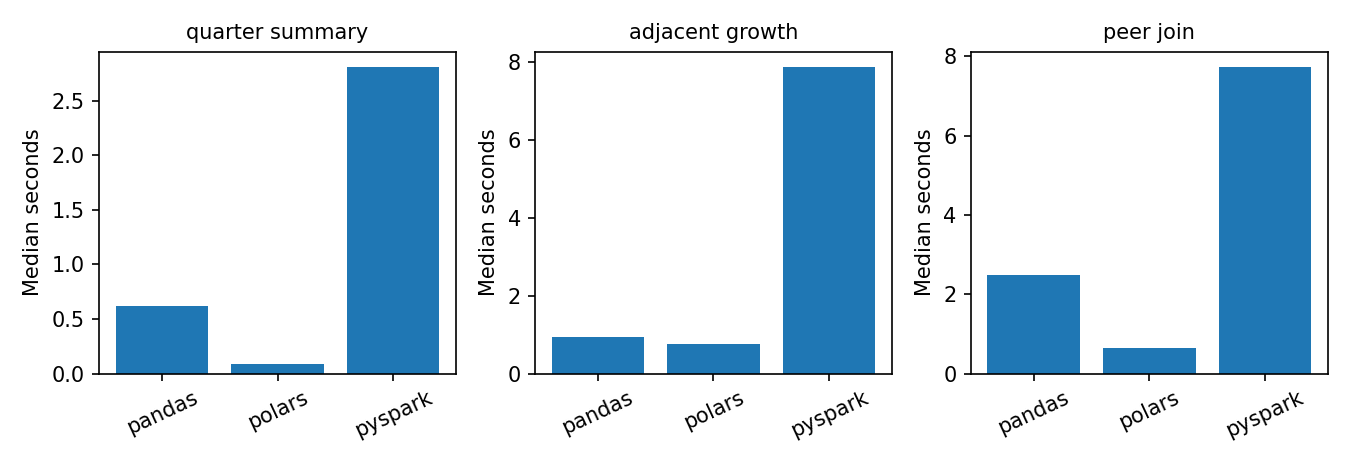

All saved warm-up and measured results passed row accounting, cross-engine parity and replica-scaling checks.


In [7]:
import pandas as pd
from IPython.display import display,Markdown,Image,HTML

def show(title,df,formats=None):
    display(Markdown(f"**{title}**"))
    display(df.style.hide(axis="index").format(formats or {},na_rep="—"))
    display(HTML('<div style="height:18px"></div>'))
def fig(title,file):
    display(Markdown(f"**{title}**"))
    display(Image(filename=str(EVIDENCE/file),width=680))
    display(HTML('<div style="height:22px"></div>'))
summary=pd.read_csv(EVIDENCE/"summary.csv")
base=summary[(summary.scale==1)&(summary.threads==2)]
show("Table 1. Actual-scale processing performance",base.drop(columns=["scale","threads"]),{"input_rows":"{:,}","median_seconds":"{:.4f}","iqr_seconds":"{:.4f}","median_peak_rss_mib":"{:.1f}","median_incremental_rss_mib":"{:.1f}"})
wide=base.pivot(index="workload",columns="engine",values="median_seconds").reset_index()
wide["pandas_over_polars"]=wide.pandas/wide.polars
wide["spark_over_polars"]=wide.pyspark/wide.polars
show("Table 2. Actual-scale median latency ratios",wide,{x:"{:.3f}" for x in wide.columns if x!="workload"})
fig("Figure 1. Actual-scale median latency by workload","runtime.png")
print("All saved warm-up and measured results passed row accounting, cross-engine parity and replica-scaling checks.")

## 7. Inspect optimized and physical execution plans
Read the recorded plans. Explain projection, filter, aggregation, ordering and join strategy from actual operators; do not infer a distributed network cost from a local Spark exchange. A lazy plan is not proof that every operator streams.

In [8]:
for workload in ("quarter_summary","adjacent_growth","peer_join"):
    for engine in ("polars","pyspark"):
        display(Markdown(f"**{engine} — {workload}**"))
        plan=(EVIDENCE/"plans"/f"1x_{engine}_{workload}_2t.txt").read_text()
        print(plan)
        lines=[line.strip() for line in plan.splitlines() if any(k in line.lower() for k in ("project","selection","pushedfilters","readschema","exchange","window","shift(","sort","join","aggregate"))]
        if lines:
            print("\nSelected operator evidence:")
            print("\n".join(lines[:12]))
display(Markdown("""**Interpretation.** Projection limits the physical columns required by each workload; the summary date predicate may be pushed into the Parquet scan. The growth workload requires CERT-specific ordering before shifting, and retains the full available history to avoid boundary artifacts. The peer workload builds a unique state–quarter mean table and joins it to observations, preserving row cardinality. Spark aggregation, sorting and joins can introduce exchanges; inspect the actual adaptive plan and join strategy above. Under local execution, exchanges are local redistribution rather than measured network traffic. Polars' optimized lazy plan does not establish out-of-core execution."""))

**polars — quarter_summary**

SORT BY [col("REPDTE")]
  AGGREGATE[maintain_order: false]
    [len().alias("ROWS"), when([(col("ASSET").count()) > (0)]).then(col("ASSET").sum()).otherwise(null.cast(Float64)).alias("ASSETS"), when([(col("DEP").count()) > (0)]).then(col("DEP").sum()).otherwise(null.cast(Float64)).alias("DEPOSITS"), col("ROA").mean().alias("MEAN_ROA"), col("DQ_ROE_ABS_GT_100").strict_cast(Int64).sum().alias("EXTREME_ROE")] BY [col("REPDTE")]
    FROM
    Parquet SCAN [/content/fdic_processing_scratch/part3-y8p7ahnw/stage/1/1984-03-31.parquet, ... 169 other sources]
    PROJECT 5/8 COLUMNS
    SELECTION: [(col("REPDTE")) >= (2000-03-31)]
    ESTIMATED ROWS: 3048100

Selected operator evidence:
SORT BY [col("REPDTE")]
AGGREGATE[maintain_order: false]
PROJECT 5/8 COLUMNS
SELECTION: [(col("REPDTE")) >= (2000-03-31)]


**pyspark — quarter_summary**

== Physical Plan ==
AdaptiveSparkPlan (20)
+- == Final Plan ==
   ResultQueryStage (13)
   +- * Sort (12)
      +- AQEShuffleRead (11)
         +- ShuffleQueryStage (10), Statistics(sizeInBytes=5.8 KiB, rowCount=106)
            +- Exchange (9)
               +- * HashAggregate (8)
                  +- AQEShuffleRead (7)
                     +- ShuffleQueryStage (6), Statistics(sizeInBytes=6.6 KiB, rowCount=106)
                        +- Exchange (5)
                           +- * HashAggregate (4)
                              +- * Filter (3)
                                 +- * ColumnarToRow (2)
                                    +- Scan parquet  (1)
+- == Initial Plan ==
   Sort (19)
   +- Exchange (18)
      +- HashAggregate (17)
         +- Exchange (16)
            +- HashAggregate (15)
               +- Filter (14)
                  +- Scan parquet  (1)


(1) Scan parquet 
Output [5]: [REPDTE#237, ASSET#238, DEP#239, ROA#240, DQ_ROE_ABS_GT_100#242]
Batched: true
Location: In

**polars — adjacent_growth**

SORT BY [col("REPDTE")]
  AGGREGATE[maintain_order: false]
    [len().alias("ROWS"), col("adjacent").strict_cast(Int64).sum().alias("ADJACENT"), col("growth").count().alias("VALID_GROWTH"), col("growth").mean().alias("MEAN_GROWTH")] BY [col("REPDTE")]
    FROM
     WITH_COLUMNS:
     [when([([(col("adjacent")) & ([(col("prev_asset")) > (0.0)])]) & (col("ASSET").is_not_null())]).then([(100.0) * ([([(col("ASSET")) / (col("prev_asset"))]) - (1.0)])]).otherwise(null.cast(Float64)).alias("growth")] 
       WITH_COLUMNS:
       [[([(col("idx")) - (col("prev_idx"))]) == (1)].fill_null([false]).alias("adjacent")] 
        simple π 6/6 ["CERT", "REPDTE", "ASSET", ... 3 other columns]
           WITH_COLUMNS:
           [col("idx").shift([dyn int: 1]).over([col("CERT")]).alias("prev_idx")] 
             WITH_COLUMNS:
             [[([(col("REPDTE").dt.year()) * (4)]) + (col("REPDTE").dt.quarter().cast(Int32))].alias("idx"), col("ASSET").shift([dyn int: 1]).over([col("CERT")]).alias("prev_asset")

... (3 outputs left out)

SORT BY [col("REPDTE")]
  AGGREGATE[maintain_order: false]
    [len().alias("ROWS"), col("dev").count().alias("MATCHED"), col("dev").mean().alias("MEAN_ABS_DEVIATION")] BY [col("REPDTE")]
    FROM
     WITH_COLUMNS:
     [[(col("ROA")) - (col("peer"))].abs().alias("dev")] 
      simple π 3/3 ["REPDTE", "ROA", "peer"]
        LEFT JOIN:
        LEFT PLAN ON: [col("REPDTE"), col("STNAME")]
          CACHE[id: 72cc2f58-ecdd-4ad8-af12-f6ca3743d8c6]
            simple π 3/3 ["REPDTE", "STNAME", "ROA"]
              Parquet SCAN [/content/fdic_processing_scratch/part3-y8p7ahnw/stage/1/1984-03-31.parquet, ... 169 other sources]
              PROJECT 3/8 COLUMNS
              ESTIMATED ROWS: 3048100
        RIGHT PLAN ON: [col("REPDTE"), col("STNAME")]
          AGGREGATE[maintain_order: false]
            [col("ROA").mean().alias("peer")] BY [col("REPDTE"), col("STNAME")]
            FROM
            simple π 3/3 ["ROA", "REPDTE", "STNAME"]
              FILTER [(col("ROA").is_not_null()) & (

**pyspark — peer_join**

== Physical Plan ==
AdaptiveSparkPlan (42)
+- == Final Plan ==
   ResultQueryStage (27)
   +- * Sort (26)
      +- AQEShuffleRead (25)
         +- ShuffleQueryStage (24), Statistics(sizeInBytes=6.6 KiB, rowCount=170)
            +- Exchange (23)
               +- * HashAggregate (22)
                  +- AQEShuffleRead (21)
                     +- ShuffleQueryStage (20), Statistics(sizeInBytes=8.0 KiB, rowCount=170)
                        +- Exchange (19)
                           +- * HashAggregate (18)
                              +- * Project (17)
                                 +- * BroadcastHashJoin LeftOuter BuildRight (16)
                                    :- AQEShuffleRead (5)
                                    :  +- ShuffleQueryStage (4), Statistics(sizeInBytes=68.4 MiB, rowCount=1.68E+6)
                                    :     +- Exchange (3)
                                    :        +- * ColumnarToRow (2)
                                    :           +- Scan pa

**Interpretation.** Projection limits the physical columns required by each workload; the summary date predicate may be pushed into the Parquet scan. The growth workload requires CERT-specific ordering before shifting, and retains the full available history to avoid boundary artifacts. The peer workload builds a unique state–quarter mean table and joins it to observations, preserving row cardinality. Spark aggregation, sorting and joins can introduce exchanges; inspect the actual adaptive plan and join strategy above. Under local execution, exchanges are local redistribution rather than measured network traffic. Polars' optimized lazy plan does not establish out-of-core execution.

## 8. Synthetic stress scaling and thread sensitivity
The larger inputs are replicated bank histories, not new institutions. Compare measured time, logical row throughput and sampled memory. The Amdahl fraction is an apparent diagnostic under ideal assumptions; values outside [0,1] invalidate that interpretation. No Spark cluster was measured.

**Table 3. Staged benchmark inputs**

scale,rows,filtered_rows,size_mib,files
1,"1,682,739","751,323",56.43,170
5,"8,413,695","3,756,615",148.92,170
10,"16,827,390","7,513,230",281.65,170


**Table 4. Single-machine scaling**

engine,workload,scale,input_rows,time_ratio,rows_per_second
pandas,quarter_summary,1,"751,323",1.000,"1,209,018"
pandas,quarter_summary,5,"3,756,615",2.675,"2,259,926"
pandas,quarter_summary,10,"7,513,230",5.596,"2,160,443"
pandas,adjacent_growth,1,"1,682,739",1.000,"1,807,107"
pandas,adjacent_growth,5,"8,413,695",5.410,"1,670,021"
pandas,adjacent_growth,10,"16,827,390",11.787,"1,533,157"
pandas,peer_join,1,"1,682,739",1.000,"676,093"
pandas,peer_join,5,"8,413,695",4.168,"811,052"
pandas,peer_join,10,"16,827,390",7.305,"925,550"
polars,quarter_summary,1,"751,323",1.000,"8,510,331"


**Table 5. Polars thread-count sensitivity**

workload,one_thread_s,two_threads_s,speedup,efficiency,apparent_serial_fraction
quarter_summary,0.153,0.088,1.732,0.866,0.154
adjacent_growth,1.556,0.771,2.019,1.010,-0.009
peer_join,0.448,0.640,0.700,0.350,1.859


**Figure 2. Runtime under synthetic scale-up**

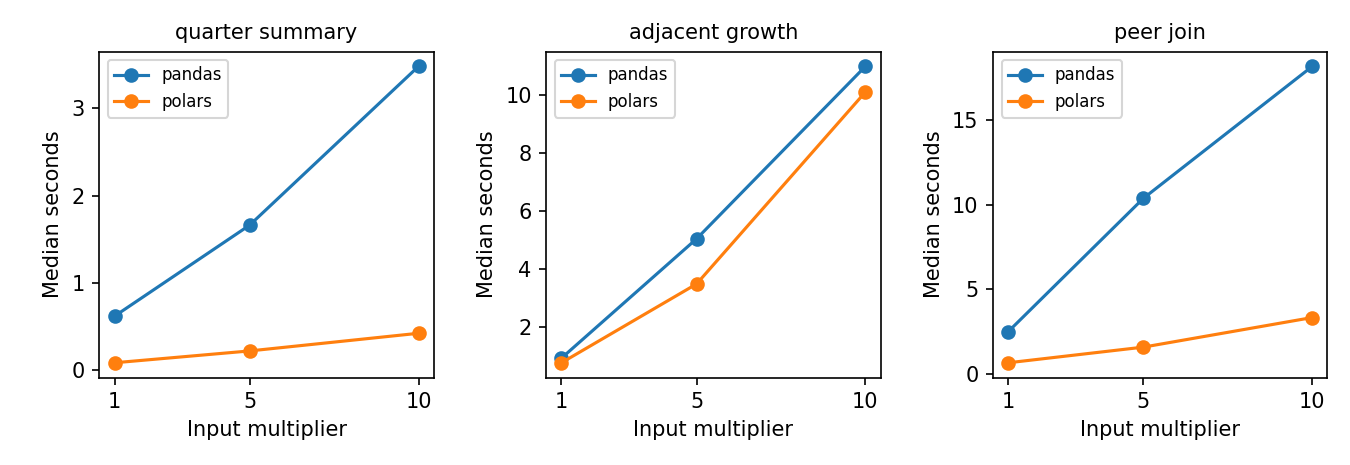

**Figure 3. Sampled peak process-tree memory under scale-up**

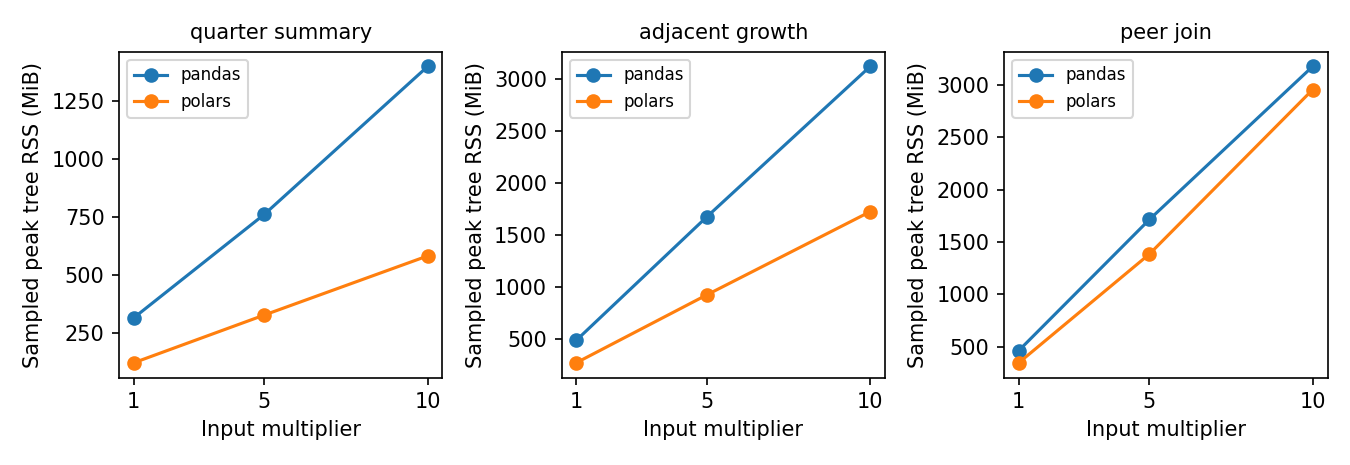

**Table 6. Measured stress-test runtime and memory**

scale,engine,workload,n,input_rows,median_seconds,iqr_seconds,median_peak_rss_mib,median_incremental_rss_mib
5,pandas,adjacent_growth,3,"8,413,695",5.0381,0.9681,1672.5,661.5
5,pandas,peer_join,3,"8,413,695",10.3738,1.2187,1714.5,857.0
5,pandas,quarter_summary,3,"3,756,615",1.6623,0.0691,762.4,303.7
5,polars,adjacent_growth,3,"8,413,695",3.4839,0.5059,922.3,22.0
5,polars,peer_join,3,"8,413,695",1.5659,0.4481,1384.5,52.8
5,polars,quarter_summary,3,"3,756,615",0.2236,0.0165,328.6,9.3
10,pandas,adjacent_growth,3,"16,827,390",10.9757,0.9102,3117.2,1407.2
10,pandas,peer_join,3,"16,827,390",18.1810,0.5095,3177.0,1716.6
10,pandas,quarter_summary,3,"7,513,230",3.4776,0.9801,1399.4,511.3
10,polars,adjacent_growth,3,"16,827,390",10.0922,1.4586,1721.6,8.3


In [9]:
stage=json.loads((EVIDENCE/"staging.json").read_text())
show("Table 3. Staged benchmark inputs",pd.DataFrame([{"scale":k,"rows":v["rows"],"filtered_rows":v["filtered_rows"],"size_mib":v["bytes"]/2**20,"files":len(v["files"])} for k,v in stage.items()]),{"rows":"{:,}","filtered_rows":"{:,}","size_mib":"{:.2f}"})
show("Table 4. Single-machine scaling",pd.read_csv(EVIDENCE/"scaling.csv"),{"input_rows":"{:,}","time_ratio":"{:.3f}","rows_per_second":"{:,.0f}"})
show("Table 5. Polars thread-count sensitivity",pd.read_csv(EVIDENCE/"parallelism.csv"),{k:"{:.3f}" for k in ("one_thread_s","two_threads_s","speedup","efficiency","apparent_serial_fraction")})
fig("Figure 2. Runtime under synthetic scale-up","scaling.png")
fig("Figure 3. Sampled peak process-tree memory under scale-up","memory.png")
show("Table 6. Measured stress-test runtime and memory",summary[(summary.scale>1)&(summary.threads==2)].drop(columns=["threads"]),{"input_rows":"{:,}","median_seconds":"{:.4f}","iqr_seconds":"{:.4f}","median_peak_rss_mib":"{:.1f}","median_incremental_rss_mib":"{:.1f}"})

## 9. Cluster decision and handoff
The verified evidence supports a workload-specific decision about local processing. Compare measured 1× and synthetic 5×/10× performance against memory and service requirements. A multi-node deployment requires a separate measurement of communication, I/O, provisioning and cost. Part 4 reads the original verified Silver panel and separate dated event evidence; no synthetic rows, benchmark outputs or retrospective terminal status become model inputs.

Save the executed notebook with outputs to the public repository. Preserve evidence in the workspace; do not commit data files.